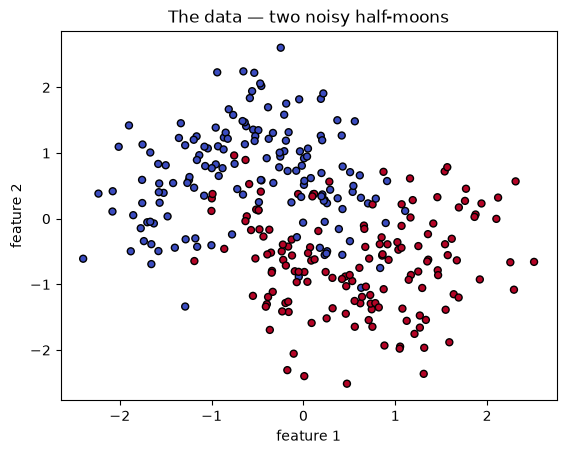

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

# Two interleaving half-moons with some noise — needs a curved boundary
X, y = make_moons(n_samples=300, noise=0.3, random_state=42)
X = StandardScaler().fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=25)
plt.title('The data — two noisy half-moons')
plt.xlabel('feature 1'); plt.ylabel('feature 2')
plt.show()

In [8]:
def plot_boundary(ax, clf, title):
    """Shade the decision regions of a fitted classifier, with the data on top."""
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train,
               cmap='coolwarm', edgecolors='k', s=20)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])

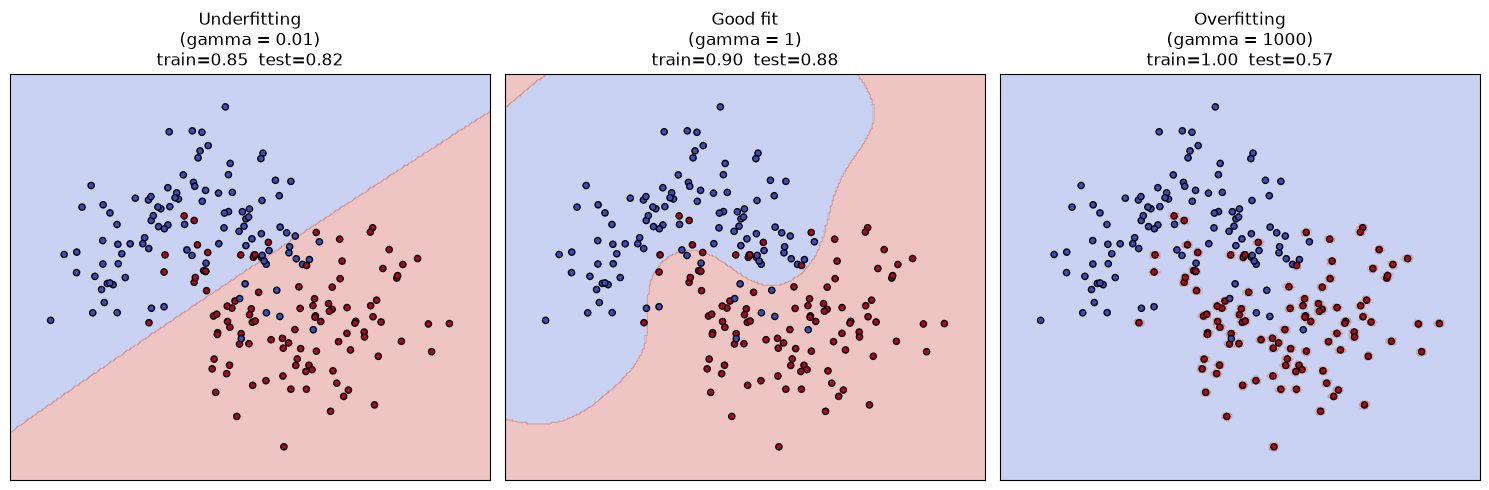

In [9]:
settings = [
    (0.01, 'Underfitting\n(gamma = 0.01)'),
    (1,    'Good fit\n(gamma = 1)'),
    (1000, 'Overfitting\n(gamma = 1000)'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (gamma, title) in zip(axes, settings):
    clf = SVC(kernel='rbf', gamma=gamma, C=1).fit(X_train, y_train)
    train_acc = clf.score(X_train, y_train)
    test_acc = clf.score(X_test, y_test)
    plot_boundary(ax, clf, f'{title}\ntrain={train_acc:.2f}  test={test_acc:.2f}')
plt.tight_layout()
plt.show()

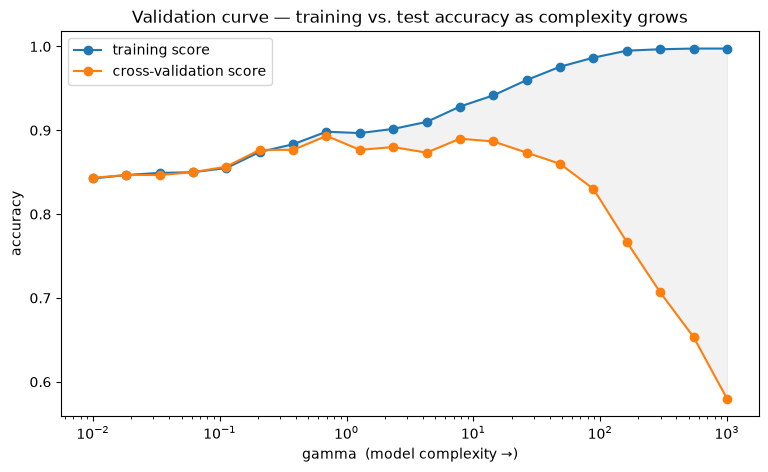

In [10]:
from sklearn.model_selection import validation_curve

gamma_range = np.logspace(-2, 3, 20)   # from 0.01 to 1000
train_scores, test_scores = validation_curve(
    SVC(kernel='rbf', C=1), X, y,
    param_name='gamma', param_range=gamma_range,
    cv=5, scoring='accuracy'
)

train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.semilogx(gamma_range, train_mean, 'o-', label='training score')
plt.semilogx(gamma_range, test_mean, 'o-', label='cross-validation score')
plt.fill_between(gamma_range, train_mean, test_mean, alpha=0.1, color='grey')
plt.xlabel('gamma  (model complexity \u2192)')
plt.ylabel('accuracy')
plt.title('Validation curve — training vs. test accuracy as complexity grows')
plt.legend()
plt.show()